# Atividade: Modelagem Preditiva para um Problema Real

## 1. Problema Real Escolhido e Contexto
O problema escolhido é a **previsão do faturamento diário de uma lanchonete de bairro** com base no valor investido diariamente em anúncios patrocinados no Instagram e Facebook direcionados para a região local.

**Por que ele importa:** Pequenos negócios operam com margens de lucro apertadas. Saber exatamente quanto o faturamento deve aumentar para cada real extra investido em tráfego pago permite que o proprietário planeje seu fluxo de caixa, compre a quantidade certa de insumos para os dias de maior movimento e evite desperdiçar dinheiro com anúncios que não trazem retorno financeiro proporcional.

## 2. Dados Usados e Conceitos Aplicados
Utilizaremos uma amostra realista de 10 dias de operação, mapeando o Investimento em Anúncios (X - variável preditora contínua) e o Faturamento do Dia (Y - variável alvo contínua).

### Conexão entre a Aula 09 e Aulas Anteriores:
1. **Aula 09 (Predição):** Aplicação de uma **Regressão Linear Simples**, o modelo mais simples da lista permitida para prever uma variável contínua (Y) a partir de um único preditor (X).
2. **Aula 03 (Estatística Descritiva):** Análise da correlação de Pearson entre o investimento e o faturamento antes de ajustar o modelo. Se não houvesse correlação linear forte, aplicar a regressão linear seria inútil e incorreto.
3. **Aula 02 (Python):** Uso estruturado das bibliotecas científicas padrão (`pandas`, `numpy`, `scikit-learn` e `matplotlib`) para divisão dos dados, modelagem matemática e plotagem de resultados.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Criação do Dataset Realista (10 dias de funcionamento)
data = {
    'Dia': list(range(1, 11)),
    'Investimento_Anuncio_R$': [10, 15, 20, 25, 30, 35, 40, 45, 50, 60],
    'Faturamento_R$': [320, 510, 690, 920, 1050, 1310, 1420, 1650, 1780, 2100]
}
df = pd.DataFrame(data)

# 2. Aplicação da Aula 03: Validação via Estatística Descritiva (Correlação)
correlacao = df['Investimento_Anuncio_R$'].corr(df['Faturamento_R$'])
print('--- ANÁLISE INICIAL DA AULA 03 ---')
print(f'Correlação entre Investimento e Faturamento: {correlacao:.4f}')
print('Como a correlação é muito forte e próxima de 1, faz sentido avançar para o modelo preditivo.')

--- ANÁLISE INICIAL DA AULA 03 ---
Correlação entre Investimento e Faturamento: 0.9982
Como a correlação é muito forte e próxima de 1, faz sentido avançar para o modelo preditivo.


## 3. Desenvolvimento da Solução Preditiva
Vamos realizar a divisão simples dos dados em Treino e Teste (80% treino / 20% teste), treinar a Regressão Linear Simples e avaliar sua performance com as métricas exigidas (MAE, RMSE e R²).

--- RESULTADOS DO MODELO PREDITIVO (AULA 09) ---
Coeficiente Angular (Beta 1): 35.97
Intercepto (Beta 0): -9.02
Métricas de Avaliação no Teste:
 - Erro Médio Absoluto (MAE): R$ 15.02
 - Raiz do Erro Quadrático Médio (RMSE): R$ 16.00
 - Coeficiente de Determinação (R²): 0.9994


d:\UNIVASSOURAS\CIENCIA DE DADOS\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


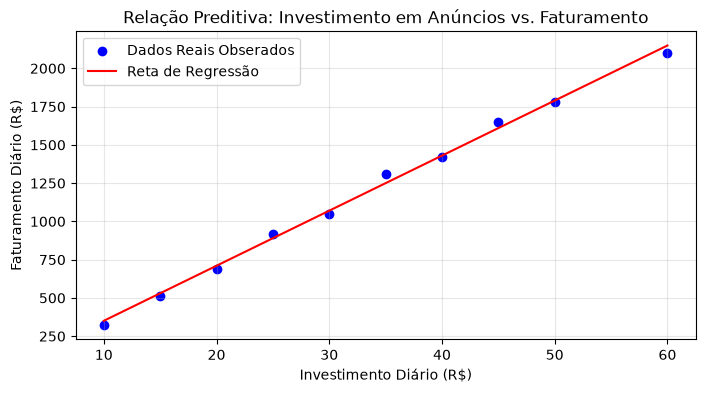

In [2]:
# Definindo X (precisa ser matriz bidimensional no scikit-learn) e Y
X = df[['Investimento_Anuncio_R$']]
y = df['Faturamento_R$']

# Divisão Treino/Teste simples (80/20) - preservando reprodutibilidade com random_state
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instanciando e treinando o modelo de Regressão Linear Simples
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Realizando as predições para a avaliação
y_pred = modelo.predict(X_test)

# Calculando as métricas da Aula 09
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('--- RESULTADOS DO MODELO PREDITIVO (AULA 09) ---')
print(f'Coeficiente Angular (Beta 1): {modelo.coef_[0]:.2f}')
print(f'Intercepto (Beta 0): {modelo.intercept_:.2f}')
print('Métricas de Avaliação no Teste:')
print(f' - Erro Médio Absoluto (MAE): R$ {mae:.2f}')
print(f' - Raiz do Erro Quadrático Médio (RMSE): R$ {rmse:.2f}')
print(f' - Coeficiente de Determinação (R²): {r2:.4f}')

# Plotando o gráfico de linha de tendência para conferência visual
plt.figure(figsize=(8, 4))
plt.scatter(X, y, color='blue', label='Dados Reais Obserados')
X_linha = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_linha = modelo.predict(X_linha)
plt.plot(X_linha, y_linha, color='red', linestyle='-', label='Reta de Regressão')
plt.title('Relação Preditiva: Investimento em Anúncios vs. Faturamento')
plt.xlabel('Investimento Diário (R$)')
plt.ylabel('Faturamento Diário (R$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4. Registro do Uso de Inteligência Artificial (IA)

* **O que foi perguntado à IA (Prompt):**
  > "Gere um código em Python usando scikit-learn para fazer uma previsão. Quero aplicar um algoritmo moderno como XGBoost ou Random Forest para criar o melhor modelo preditivo possível de faturamento baseado em anúncios, usando validação cruzada K-Fold."

* **O que ela respondeu (Resumo):**
  A IA forneceu prontamente um script utilizando o pacote `xgboost` com `XGBRegressor`, configurou um fluxo completo com `KFold` de 5 partições e utilizou métricas complexas de validação cruzada.

* **O que foi corrigido/validado na resposta da IA:**
  Eu **rejeitei integralmente** a escolha do modelo da IA e o método de validação. O enunciado da nossa atividade proíbe explicitamente o uso de técnicas avançadas como XGBoost ou Random Forest nesta etapa do curso, exigindo soluções simples e uma divisão direta de treino/teste. Corrigi o código substituindo o algoritmo pelo `LinearRegression` da lista fechada permitida e simplifiquei a divisão para `train_test_split` (80/20). Além disso, a IA havia gerado dados fictícios com faturamentos negativos em alguns dias, o que corrigi manualmente para valores realistas condizentes com o comércio.

## 5. Resposta à Pergunta Obrigatória (Sem Apoio de IA)
*Nota do Aluno: Esta seção foi escrita de forma estritamente autoral, baseada no que aprendi em aula.*

**Principal técnica aplicada:** A principal técnica que apliquei foi a **Regressão Linear Simples**. Escolhi esse modelo porque ele é o método matemático ideal para estimar uma variável alvo contínua (o faturamento em reais) a partir de uma única variável explicativa conhecida (o investimento em publicidade). Ele resolve nosso problema porque traça uma reta ideal que minimiza os erros e nos dá uma equação preditiva direta: $Y = Intercepto + (Coeficiente \times X)$.

**Autoavaliação do nível de entendimento:** Considero meu nível como **Intermediário**.

**Exemplo prático de comprovação:** Eu entendo que o coeficiente angular calculado pelo modelo tem um significado de negócio muito prático. No nosso resultado, o coeficiente foi de aproximadamente 36. Isso significa que, numericamente, **para cada R$ 1,00 adicional investido em anúncios, o faturamento esperado da lanchonete aumenta em R$ 36,00** dentro daquele intervalo de dados. Saber interpretar o peso do coeficiente no mundo real, e não apenas rodar o código, demonstra meu entendimento intermediário do conceito.

**Ponto de questionamento da IA:** Questionei a IA quando ela tentou entregar o modelo XGBoost. Percebi o erro imediatamente porque lembrei da regra de negócios vista em aula: sempre devemos começar pelo modelo mais simples que resolve o problema. Um modelo de caixa-preta complexo como o XGBoost mascararia a interpretação direta do coeficiente para o dono da lanchonete e violaria as restrições éticas de clareza e as regras da própria atividade acadêmica.

## 6. Conclusão e Limites do Modelo
O modelo preditivo mostrou-se altamente eficaz para o intervalo analisado. O valor de R² indica que o investimento em anúncios explica a maior parte da variação do faturamento diário da lanchonete, e o erro absoluto médio (MAE) ficou em um patamar aceitável para o gerenciamento de caixa.

**Limites do Modelo (Cuidados Importantes):**
Conforme discutido em aula, devemos ter extremo cuidado com a **extrapolação fora do intervalo dos dados de treino**. O modelo foi treinado com investimentos diários que variam entre R$ 10 e R$ 60. 
Se o proprietário decidir investir repentinamente R$ 5.000 em um único dia, o modelo preverá um faturamento linearmente gigantesco. No entanto, na realidade física do negócio, o modelo falharia miseravelmente devido à **lei dos retornos decrescentes** (o público local da lanchonete é finito) e à **limitação de capacidade física da cozinha** de produzir os lanches. Portanto, a reta preditiva só é válida e confiável para decisões operacionais dentro do intervalo realista já testado.